## Make simple first Benchmark Tests

As suggested by Jonathan Donges, we can make an easy first benchmark test with RedNoise and a cluster comparison scoring. <br>
The idea is to create a simple Cluster mask with ponds using RedNoise as the background. This cluster is investigated with TOAD and TOAD is tuned to match the cluster perfectly (cluster score = 1). Then we change the Signal to Noise Ratio of the orignal PONDS data and keep the same settings for TOAD. For every ratio we measure the cluster score. These two quantities are plotted against eacht other.

When this is done, we can proceed by also changing the RedNoise autocorrelation -> Create a heatmap!

/home/lukasro/Documents/TIPMIP/ponds/ponds/core.py:134: UserWarning: Background method magnitude set to 0.0. Skipping background addition to increase performance.
  warnings.warn(


(<Figure size 1600x400 with 1 Axes>,
 <Axes: title={'center': 'Time Series for Some Example Cells'}, xlabel='Time', ylabel='Value'>)

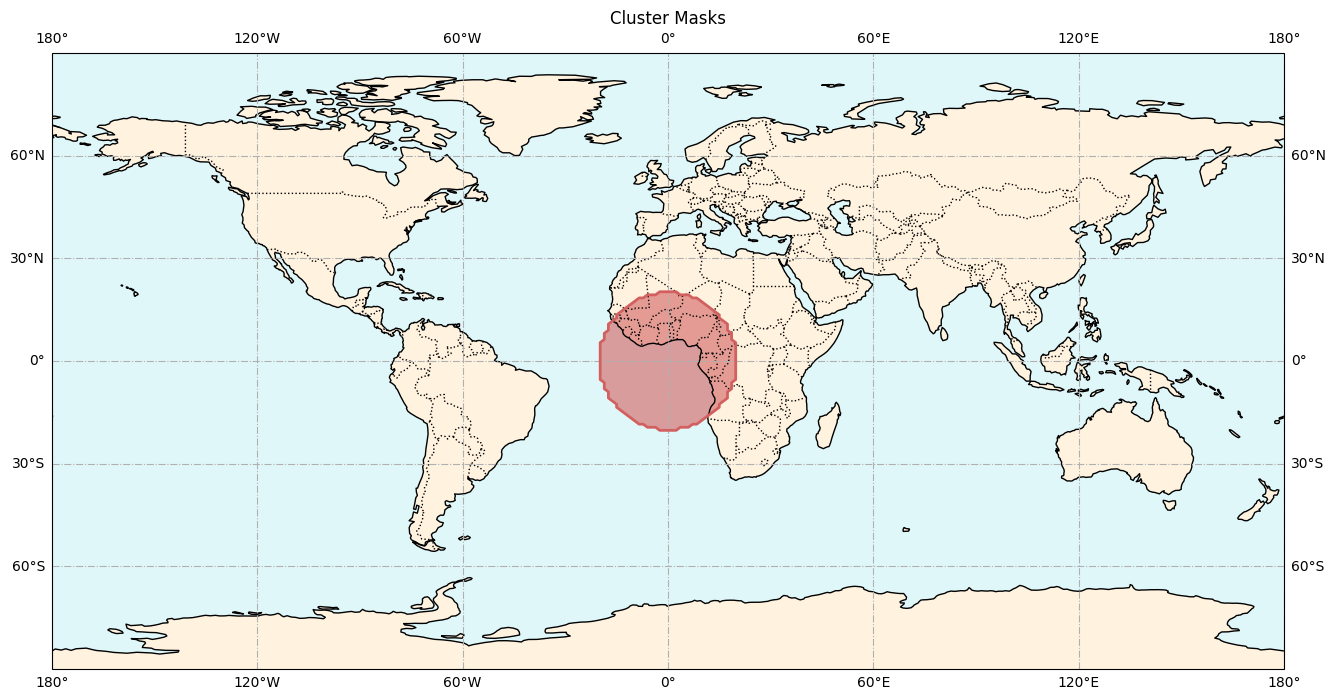

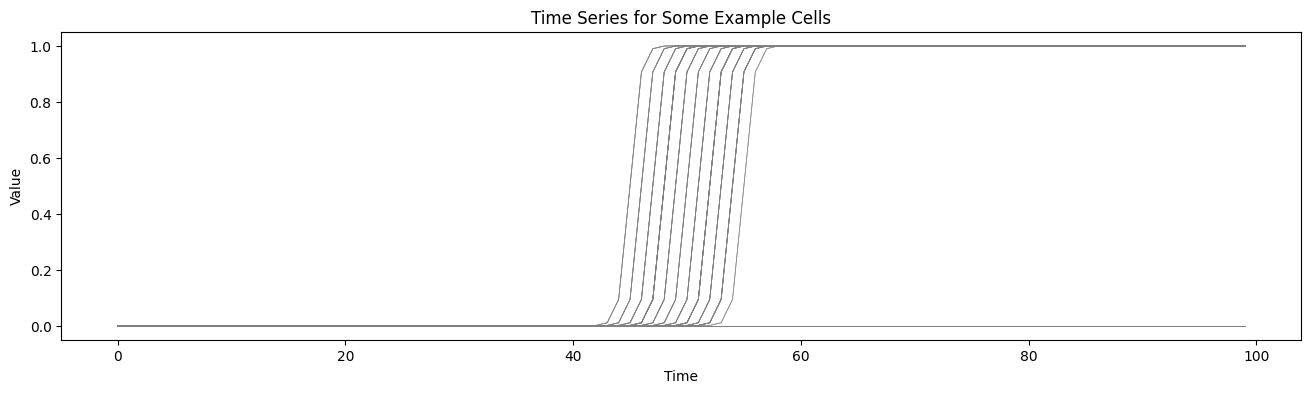

In [1]:
# create cluster with PONDS
from ponds import PONDS, SIGMOID, ELLIPSIS ,RedNoise, Noise

lat_size = 201
lon_size = 301
time_size = 100
pd = PONDS(
    lat_size=lat_size,
    lon_size=lon_size,
    time_size=time_size,
)

ac_time = 1.0
magnitude = 0.00
pd.add_background(
    background_method=RedNoise(
        ac_time=ac_time,
        magnitude=magnitude),
)

# pd.add_shift(
#     shift_method=SIGMOID(
#         shift_magnitude=1.0,
#         shift_seed = 5,
#     ),
#     shape_method=ELLIPSIS(
#         shape_seed = 2,
#     ),
# )

pd.add_shift(
    shift_method=SIGMOID(
        shift_magnitude=1.0,
        central_time = 50,
        shift_seed = 1,
    ),
    shape_method=ELLIPSIS(
        center_lat = 0,
        center_lon = 0,
        ecc_lat = 20,
        ecc_lon = 20,
    ),
    correlation_method=Noise(
        feature_name="central_time",
        corr_seed=1,
    )
)

pd.worldmap()
pd.plot_some_ts(
    ratio=0.1
)

In [2]:
# detect clusters with TOAD

from sklearn.cluster import HDBSCAN, DBSCAN
from toad.shifts import ASDETECT
from toad import TOAD
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 6)



#td = TOAD("../toad/tutorials/test_data/global_mean_summer_tas.nc") # data is in TOADtorial repo
# td.data = td.data.coarsen(lat=3, lon=3, boundary='trim').mean() # un-comment to speed up
td = TOAD(
    pd.data,
    #log_level="CRITICAL",
)
#display(td)

td.compute_shifts("ts",
    method=ASDETECT(
        ignore_nan_warnings=True,
        ))

#optuna.logging.set_verbosity(optuna.logging.CRITICAL)

#td.compute_clusters("ts",
#    shift_threshold=0.6,
#    method=HDBSCAN(
#        min_cluster_size = 20,
#        min_samples = 5,
#    ),
#    overwrite=True,
#)

td.compute_clusters("ts",
    shift_threshold=0.5,
    method=DBSCAN(
        eps=700,
        min_samples=20,
        #metric="euclidean",  # optional, defaults to 'euclidean'
    ),
    overwrite=True,
)

display(td)

INFO: New shifts variable ts_dts: min/mean/max=0.000/0.362/1.000 using 1165 grid cells. Skipped 98.1% grid cells: 0 NaN, 59336 constant.
INFO: New cluster variable ts_dts_cluster: Identified 1 cluster in 1,165 pts; Left 0.0% as noise (0 pts).


(<Figure size 3600x1800 with 2 Axes>,
 {'map': <GeoAxes: xlabel='lon', ylabel='lat'>,
  'timeseries': [<Axes: title={'center': 'clusters in ts'}, xlabel='time'>]})

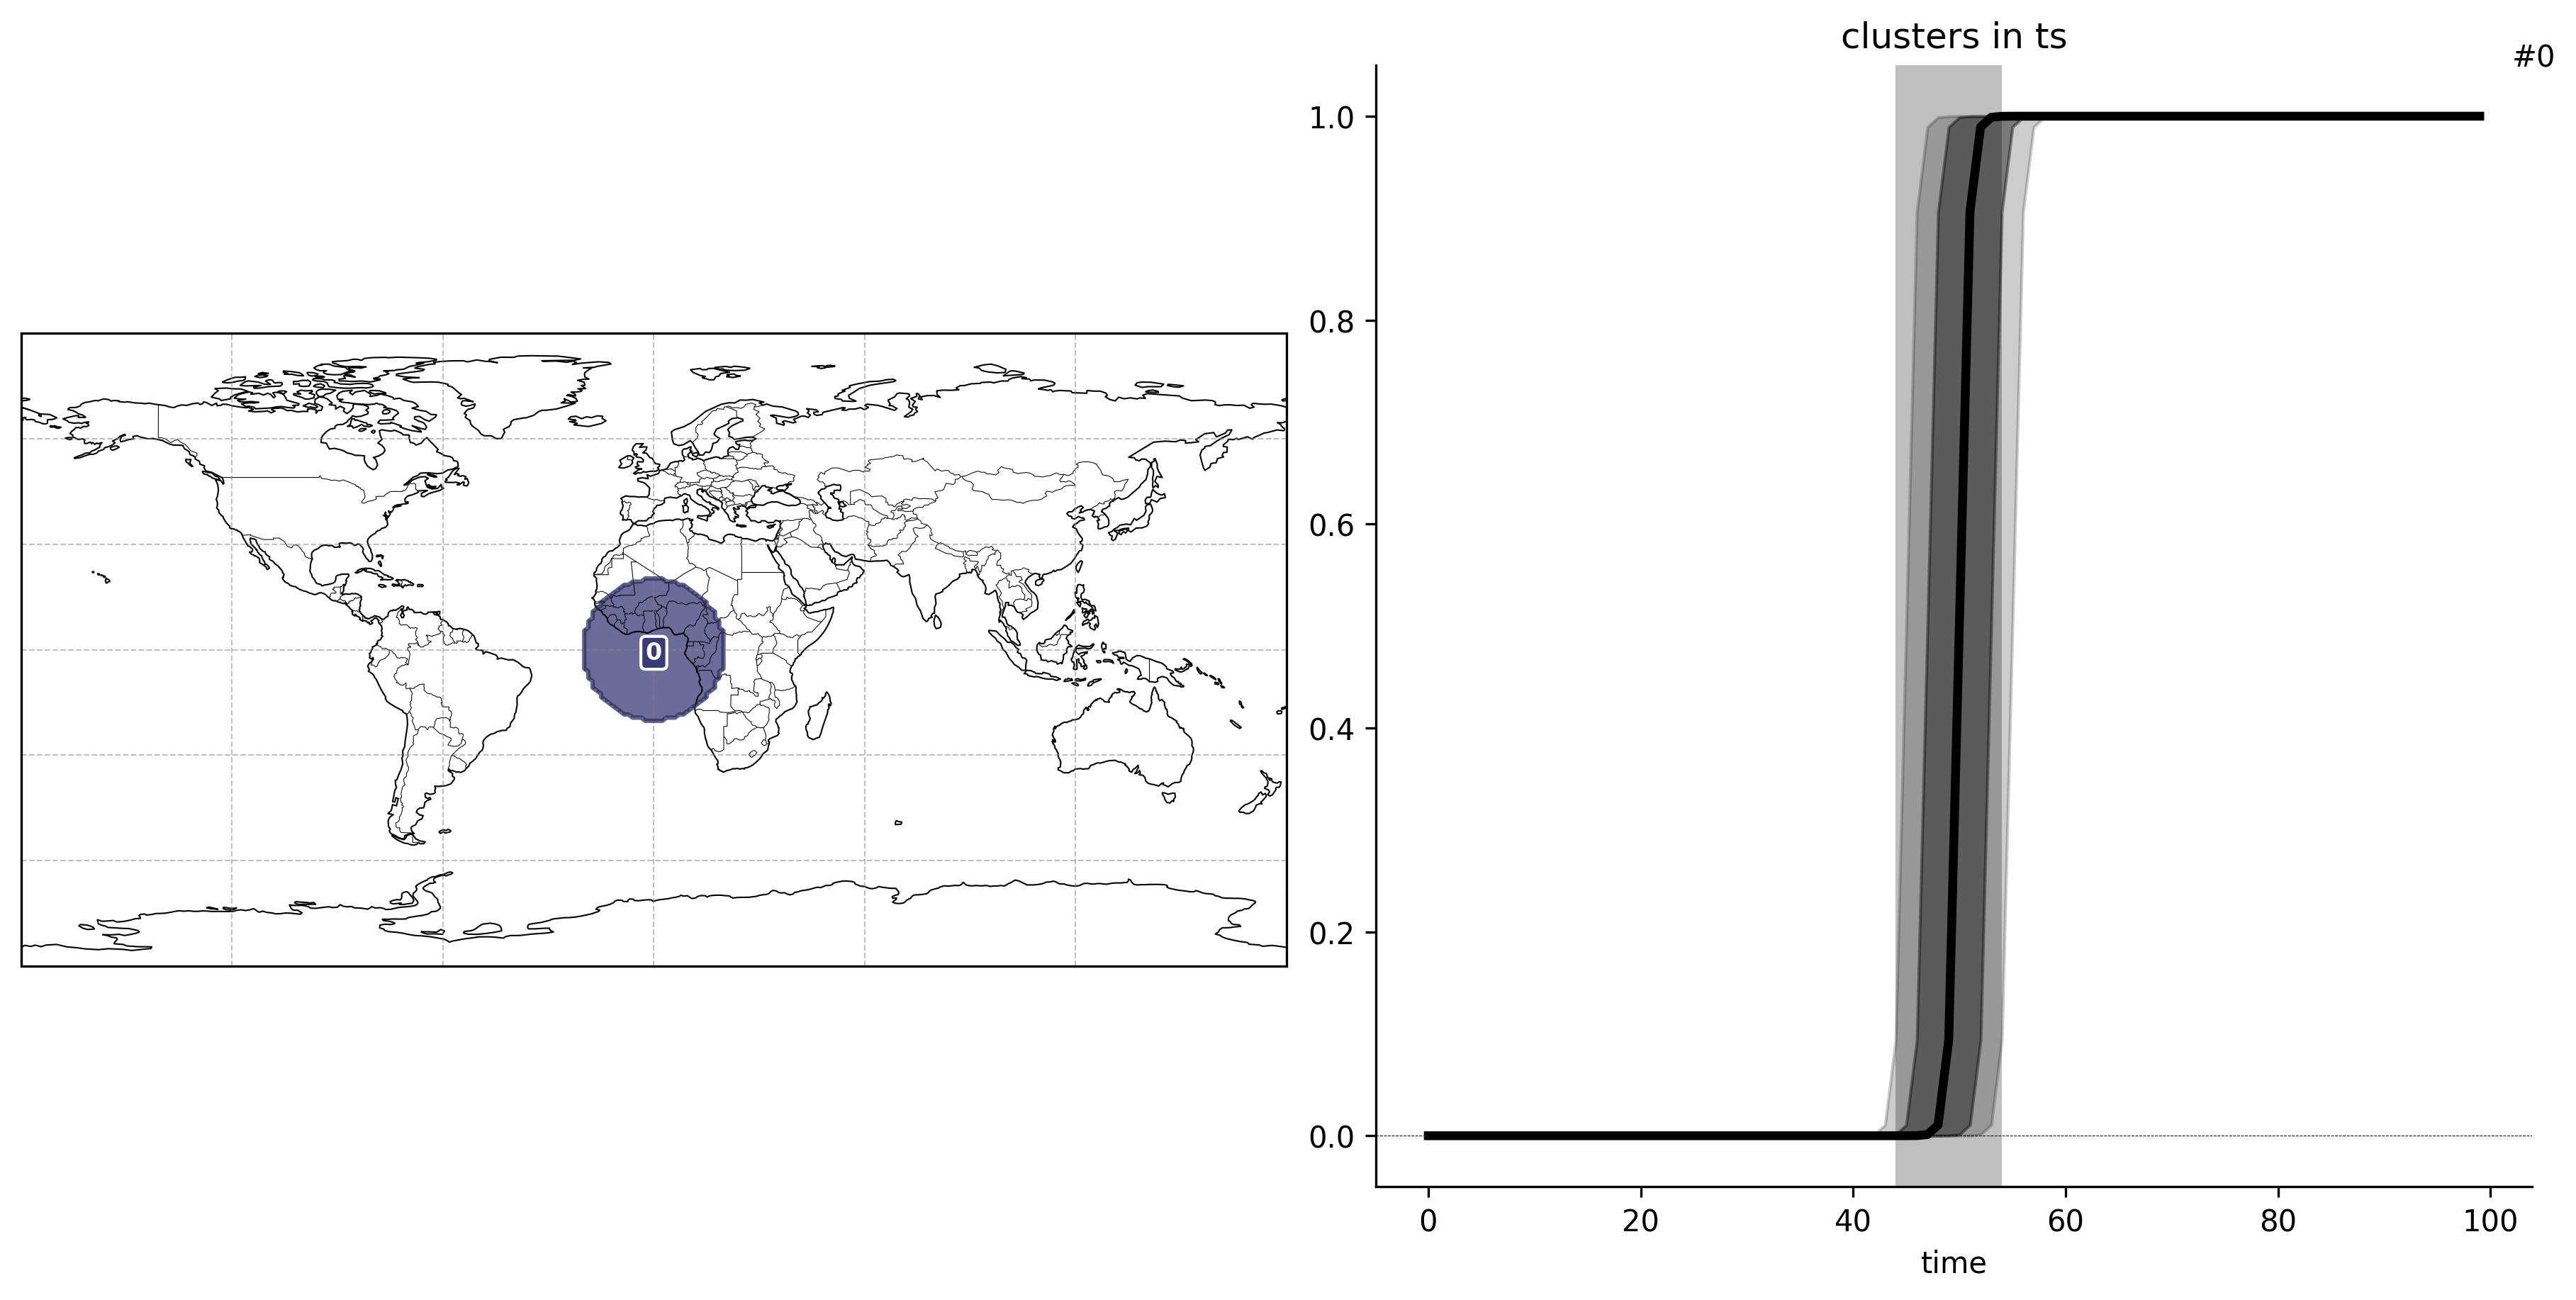

In [3]:
td.plot.overview('ts',mode="aggregated")

In [7]:
# compute cluster score
from ponds.clusterscore import extract_ponds_masks, extract_toad_masks, FC_measure, match_time, Frag, Uni

GT_masks = extract_ponds_masks(pd)
print("Ground truth masks:", len(GT_masks))
D_masks = extract_toad_masks(td)
D_masks_matched = match_time(
    GT_masks,
    D_masks,
    timestep_uncertainty=0,)
print("Detected masks:", len(D_masks_matched))

FC_scores = FC_measure(GT_masks, D_masks_matched)
print("FC scores:", FC_scores)
Frag_scores = Frag(GT_masks, D_masks_matched)
print("Fragmentation scores:", Frag_scores)
Uni_scores = Uni(GT_masks, D_masks_matched)
print("Unification scores:", Uni_scores)

Ground truth masks: 1
Detected masks: 1
FC scores: 0.2615076029084259
Fragmentation scores: [1.]
Unification scores: [1.]


In [5]:
from ponds.clusterscore import best_match, overlap_score

OS = overlap_score(GT_masks, D_masks_matched)
print("Overlap scores:\n", OS)

Overlap scores:
 [[596.]]


In [23]:
mask1 = GT_masks[0]
mask2 = D_masks_matched[0]

# compare the two masks
overlap = np.logical_and(mask1, mask2)
print("Overlap area:", np.sum(overlap))
print("Mask 1 area:", np.sum(mask1))
print("Mask 2 area:", np.sum(mask2))

Overlap area: 596
Mask 1 area: 1165
Mask 2 area: 1165


In [24]:
# find index in axis 0 where values are true of mask1
idx = np.where(mask1)[0]
print("Indices where mask1 is True:\n", idx)

# find index in axis 0 where values are true of mask2
idx = np.where(mask2)[0]
print("Indices where mask2 is True:\n", idx)

Indices where mask1 is True:
 [45 45 45 ... 55 55 55]
Indices where mask2 is True:
 [44 44 44 ... 54 54 54]


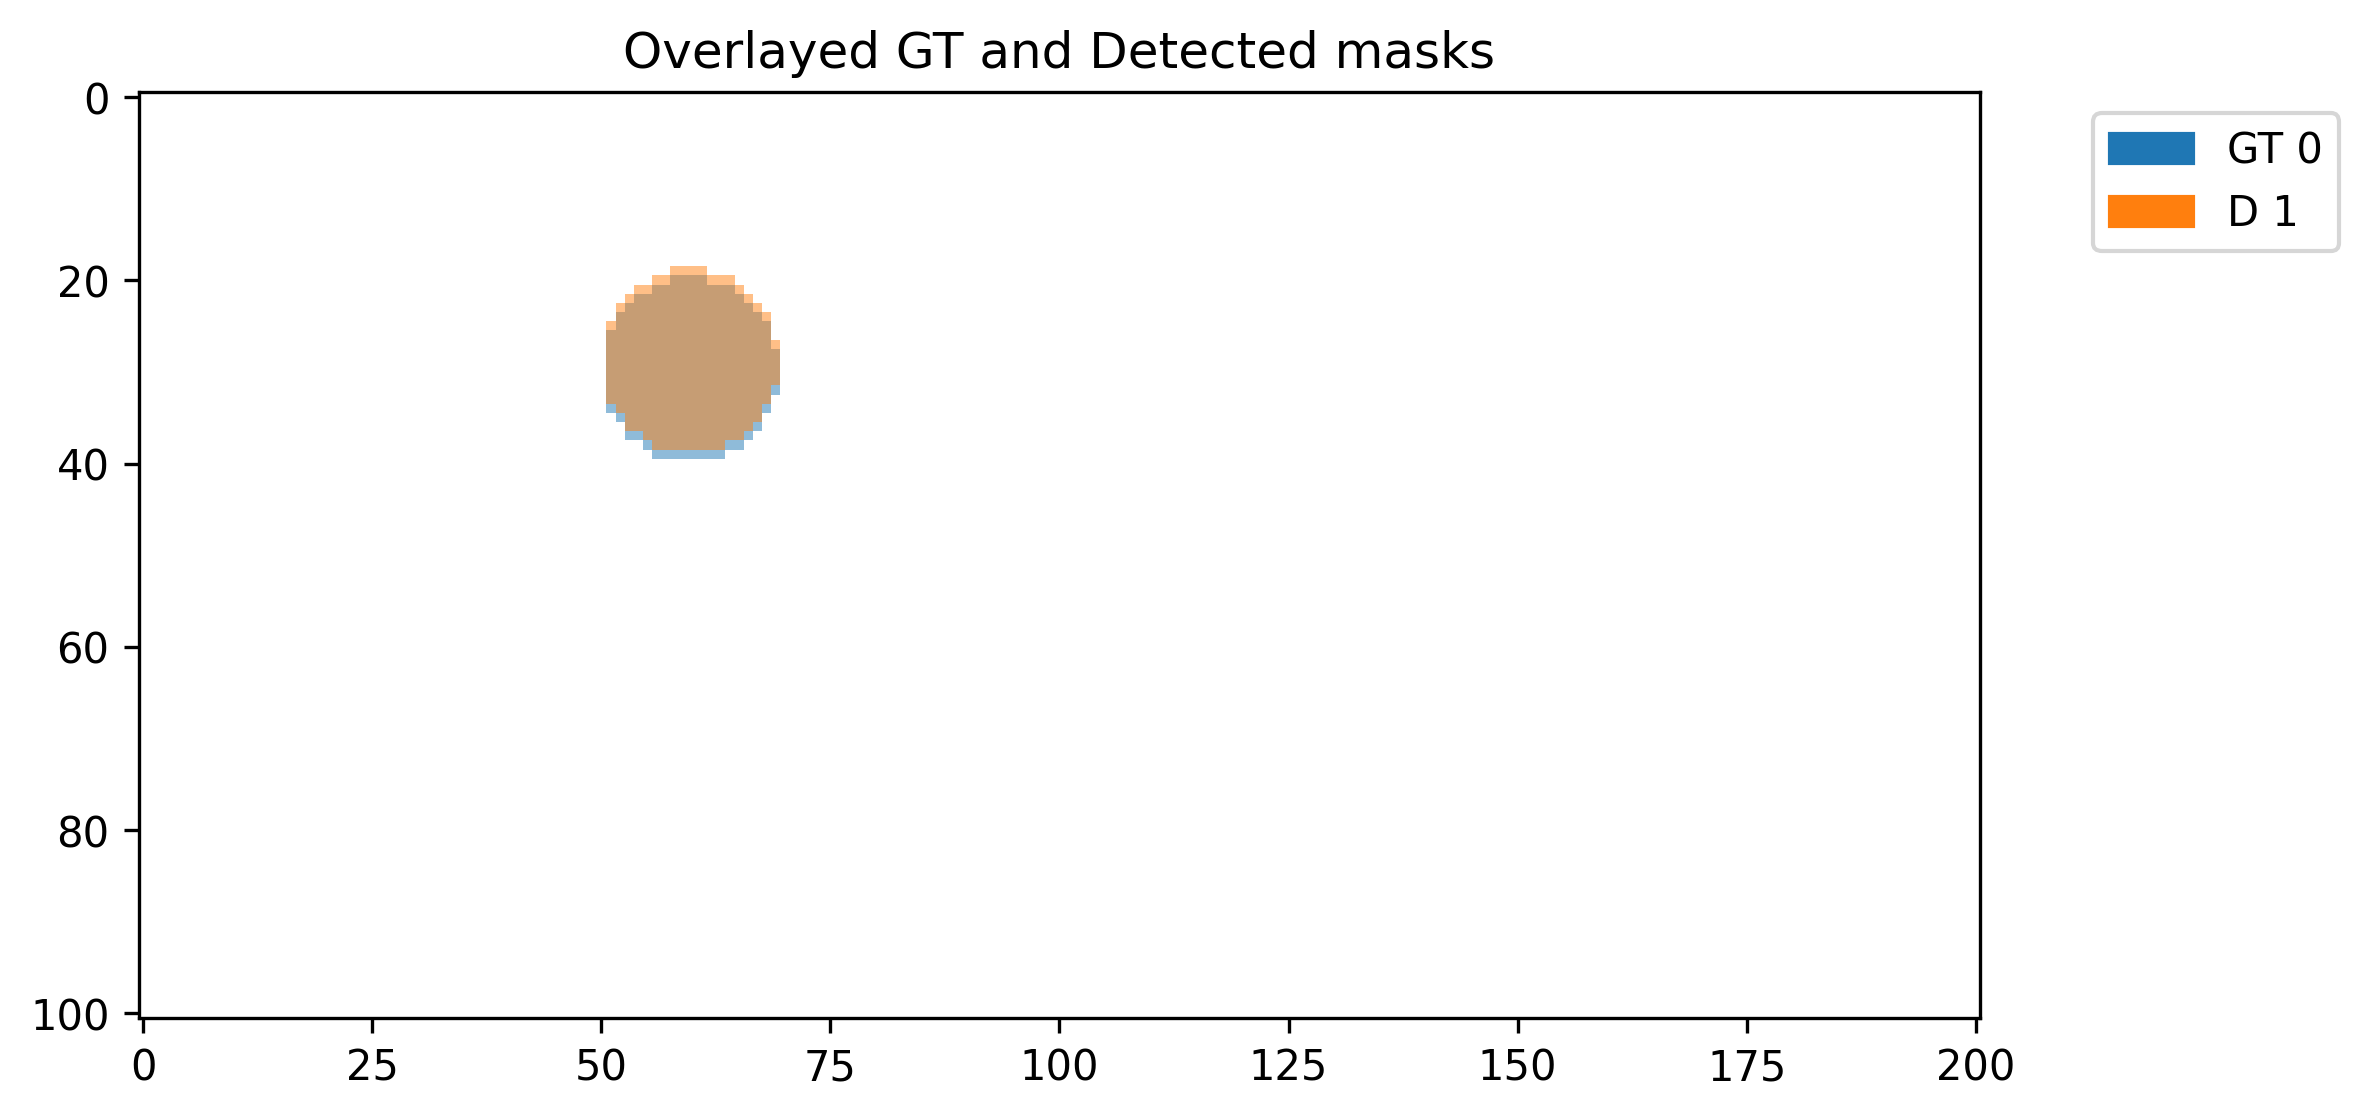

In [42]:
import matplotlib as mpl

# plot GT and D masks in one figure
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(4*len(GT_masks), 8))
# prepare base (2D) and plotting helpers
gt_keys = sorted(GT_masks.keys())[:1]
d_keys = sorted(D_masks.keys())[1:]
base = np.zeros_like(GT_masks[gt_keys[0]].sum(axis=0))

axes.imshow(base, cmap='gray_r', vmin=0, vmax=1)
import matplotlib.patches as mpatches

colors = plt.cm.tab10.colors
alpha = 0.5
handles = []

# overlay GT masks
for idx, k in enumerate(gt_keys):
    mask2d = GT_masks[k].sum(axis=0) > 0
    mask2d = np.roll(mask2d, 1, axis=0)  # shift down for better visibility
    rgba = np.zeros((base.shape[0], base.shape[1], 4), dtype=float)
    rgba[..., :3] = mpl.colors.to_rgb(colors[idx % len(colors)])
    rgba[..., 3] = mask2d.astype(float) * alpha
    axes.imshow(rgba, interpolation='none')
    handles.append(mpatches.Patch(color=colors[idx % len(colors)], label=f"GT {k}"))

# overlay Detected masks
for idx, k in enumerate(d_keys, start=len(gt_keys)):
    mask2d = D_masks[k].sum(axis=0) > 0
    rgba = np.zeros((base.shape[0], base.shape[1], 4), dtype=float)
    rgba[..., :3] = mpl.colors.to_rgb(colors[idx % len(colors)])
    rgba[..., 3] = mask2d.astype(float) * alpha
    axes.imshow(rgba, interpolation='none')
    handles.append(mpatches.Patch(color=colors[idx % len(colors)], label=f"D {k}"))

axes.set_title("Overlayed GT and Detected masks")
axes.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

(<Figure size 4800x1200 with 1 Axes>,
 <Axes: title={'center': 'Time Series for Some Example Cells'}, xlabel='Time', ylabel='Value'>)

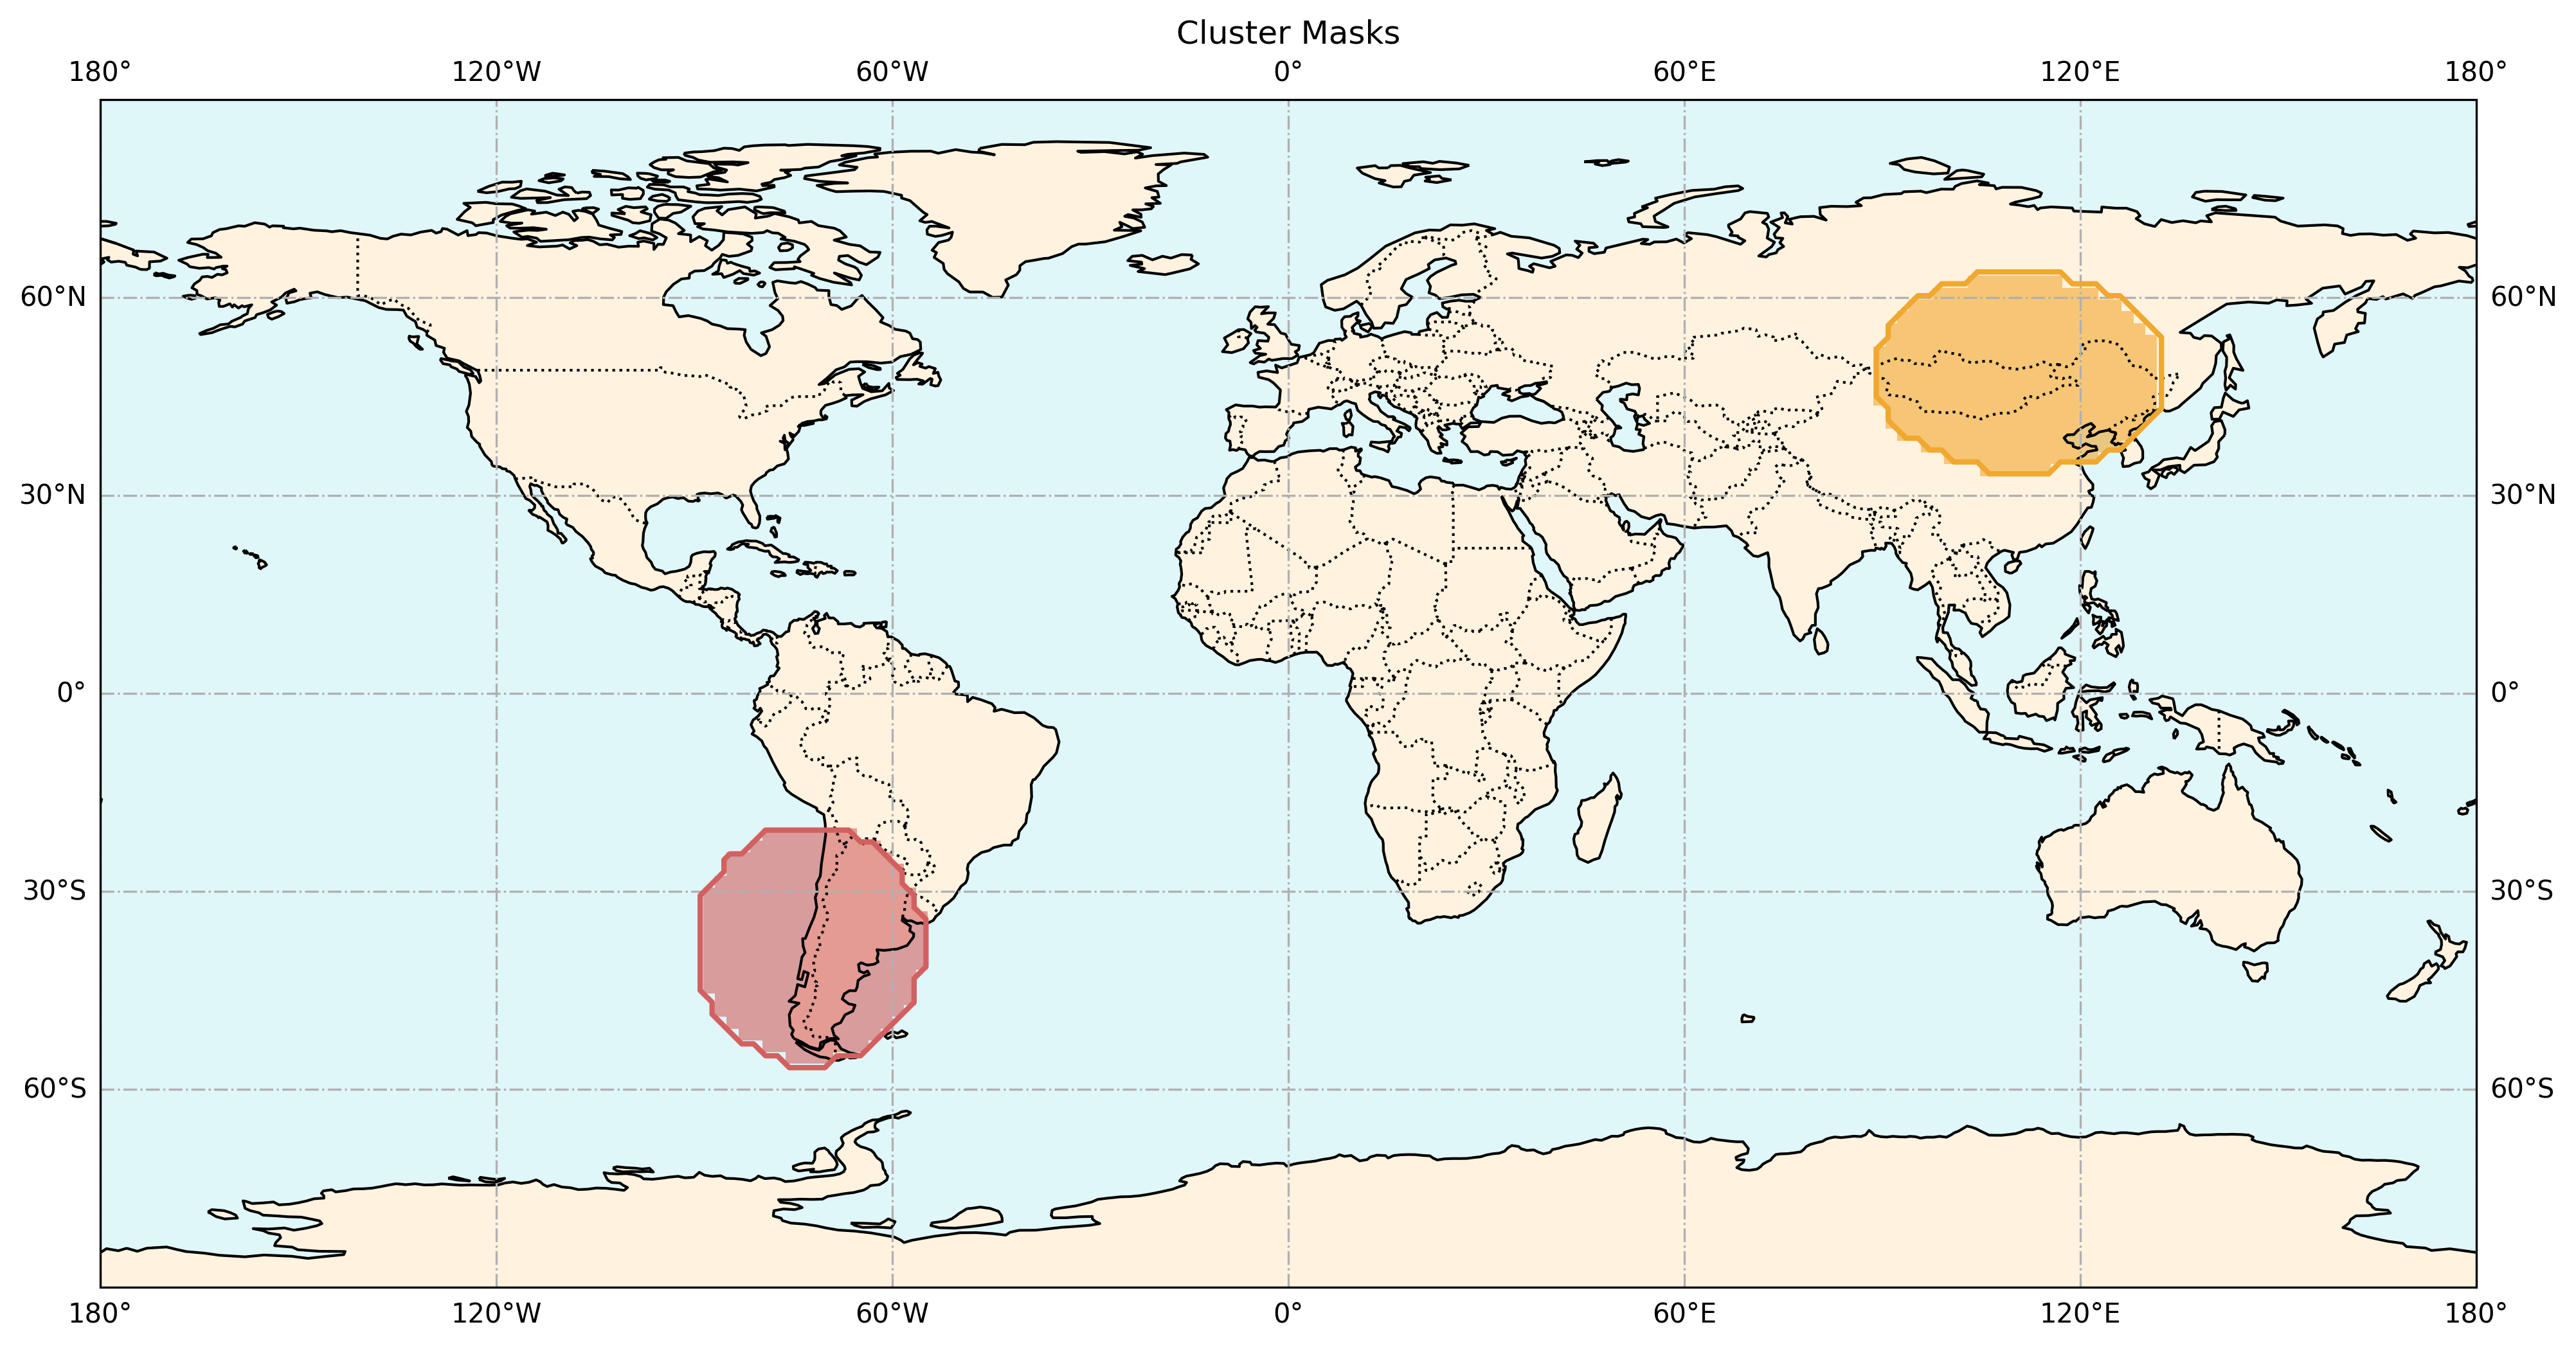

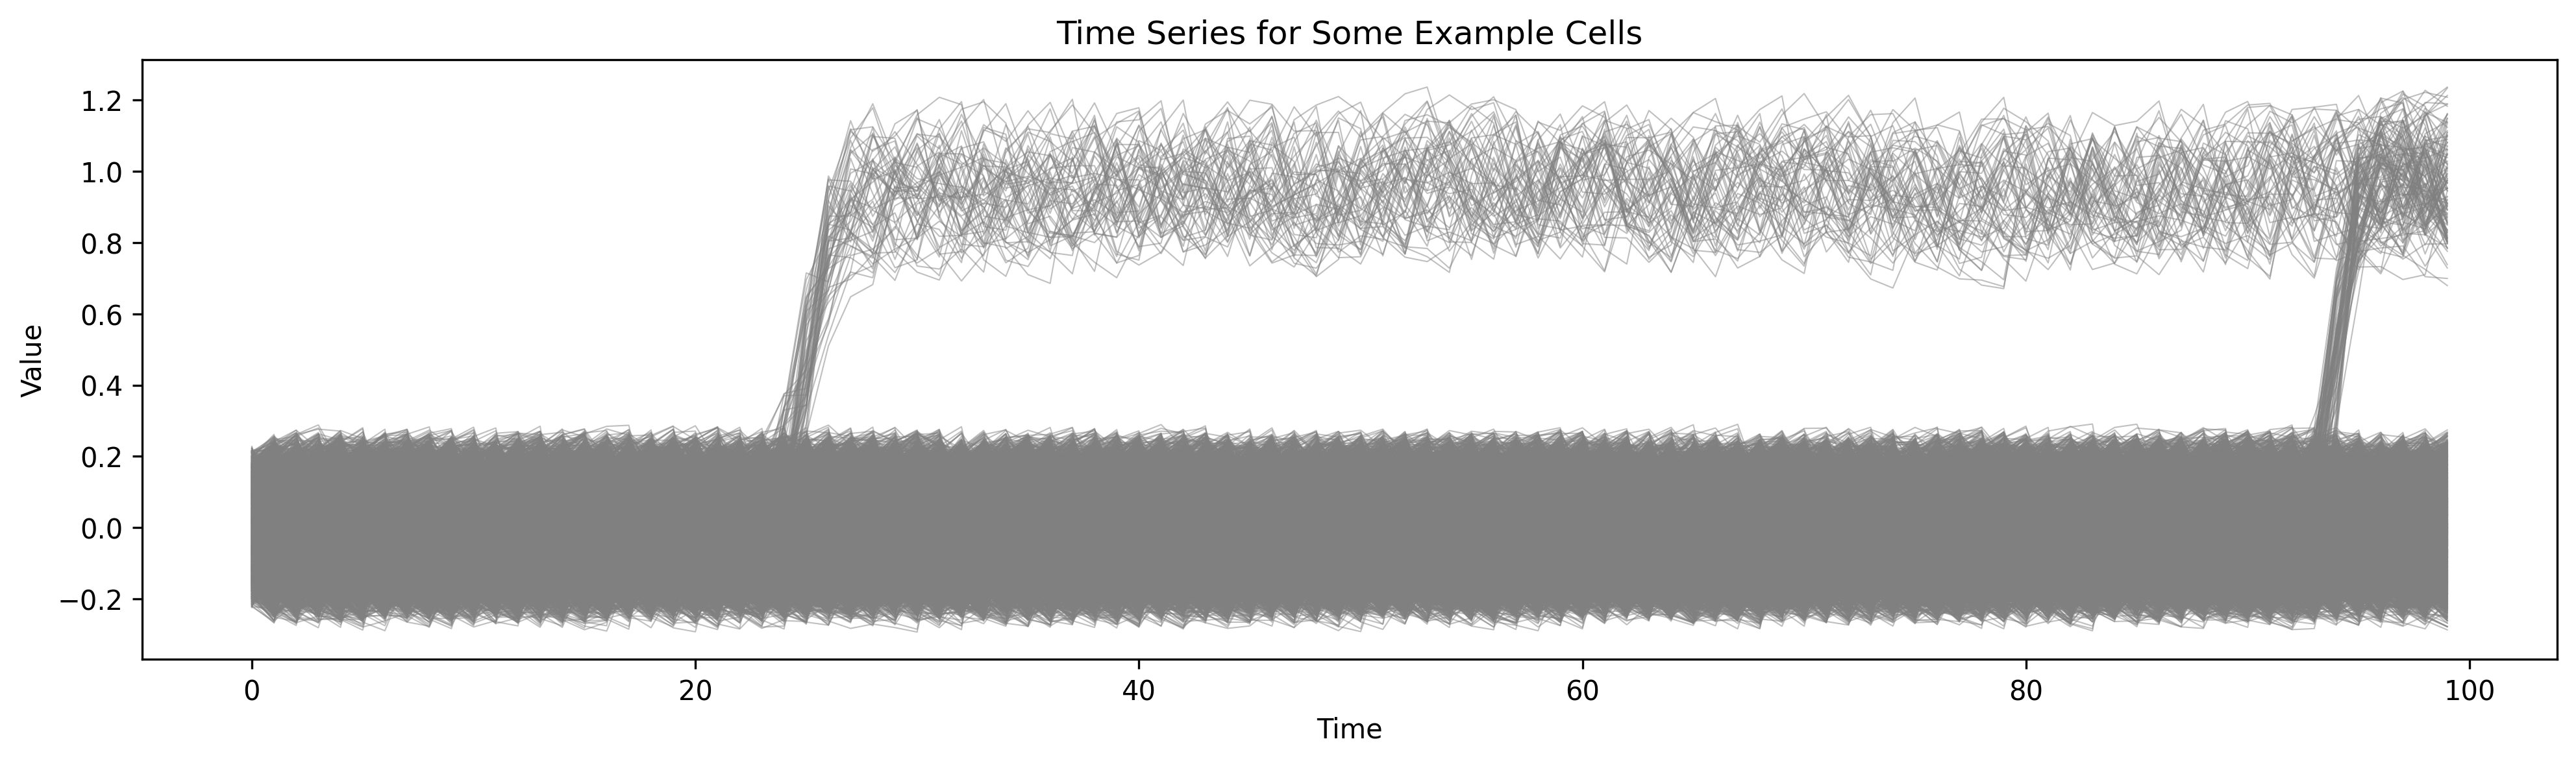

In [43]:
# create cluster with PONDS wit low SNR
from ponds import PONDS, SIGMOID, ELLIPSIS ,RedNoise

lat_size = 101
lon_size = 201
time_size = 100
pd_low = PONDS(
    lat_size=lat_size,
    lon_size=lon_size,
    time_size=time_size,
)

ac_time = 1.0
magnitude = 0.1
pd_low.add_background(
    background_method=RedNoise(
        ac_time=ac_time,
        magnitude=magnitude),
)

pd_low.add_shift(
    shift_method=SIGMOID(),
    shape_method=ELLIPSIS(
        shape_seed = 2,
    ),
)

pd_low.add_shift(
    shift_method=SIGMOID(),
    shape_method=ELLIPSIS(
        shape_seed = 5,
    ),
)

pd_low.worldmap()
pd_low.plot_some_ts(
    ratio=0.2
)

In [2]:
# detect clusters with TOAD

from sklearn.cluster import HDBSCAN
from toad.shifts import ASDETECT
from toad import TOAD
import numpy as np

#td = TOAD("../toad/tutorials/test_data/global_mean_summer_tas.nc") # data is in TOADtorial repo
# td.data = td.data.coarsen(lat=3, lon=3, boundary='trim').mean() # un-comment to speed up
td_low = TOAD(pd_low.data)
#display(td)

td_low.compute_shifts("ts",
    method=ASDETECT(
        ignore_nan_warnings=True,
        ))

td_low.compute_clusters("ts",
    shift_threshold=0.9,
    method=HDBSCAN(
        min_cluster_size=20,
        #min_samples=1,  # optional, defaults to min_cluster_size
        #cluster_selection_epsilon=0.5,  # optional, defauls to 0
        #metric="euclidean",  # optional, defaults to 'euclidean'
    ), 
    #scaler=None,
    #time_scale_factor=0.1,
    #
    overwrite=True
)

display(td_low)

INFO: New shifts variable ts_dts: min/mean/max=-0.586/0.003/0.741 using 20301 grid cells. Skipped 0.0% grid cells: 0 NaN, 0 constant.
INFO: ts_dts_cluster: Identified 0 CLUSTERS in 0 points


In [3]:
td_low.plot.cluster_overview(
    "ts",
    cluster_ids=range(5),  # plot the 5 largest clusters
    #projection="south_pole",
)

ValueError: ('No clusters found for variable', 'ts')

In [ ]:
# compute cluster score
from ponds.clusterscore import extract_G_masks, extract_D_masks, FC_measure

GT_masks = extract_G_masks(pd_low)
print("Ground truth masks:", len(GT_masks))
D_masks = extract_D_masks(td_low)
print("Detected masks:", len(D_masks))

FC_scores = FC_measure(GT_masks, D_masks)
print("FC scores:", FC_scores)

Ground truth masks: 2
Detected masks: 0
FC scores: 0.0


## Parameter Scan

In [26]:
"""
Idea of this parameter scan:
- create PONDS data with two shifts and red noise magnitude
- detect clusters with TOAD
- compute cluster scores between every PONDS GT and TOAD detected clusters
- scaning through the red noise magnitude and repeating several times per magnitude
- important: use different random seed for red noise background in every repetition! (otherwise it would be always the same)
- rest of the PONDS parameters are kept constant
"""

# create cluster with PONDS
from ponds.clusterscore import extract_G_masks, extract_D_masks, FC_measure, FB_measure, RC, Frag, Uni, match_time
from ponds import PONDS, SIGMOID, ELLIPSIS ,RedNoise
from sklearn.cluster import HDBSCAN
from toad.shifts import ASDETECT
from toad import TOAD
import numpy as np

# specify scan parameters
noise_magnitudes = np.array(
    [0.0, 0.01]#, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]
)
R = 3   # number of repetitions per noise magnitude

# make space for results
FC_results = np.zeros((len(noise_magnitudes), R))
FB_results = np.zeros((len(noise_magnitudes), R))
RC_results = np.zeros((len(noise_magnitudes), R))
Frag_results = np.zeros((len(noise_magnitudes), R, 2)) # 2 for the number of GT clusters
Uni_results = np.zeros((len(noise_magnitudes), R, 2))

# specify data resolution and other params
# - PONDS parameters
lat_size = 101
lon_size = 201
time_size = 100
ac_time = 1.0
shift_magnitude = 1.0
shift_seed1 = 5
shift_seed2 = 6
shape_seed1 = 2
shape_seed2 = 5
# - TOAD parameters
det_threshold = 0.9
min_cluster_size = 20
# - scoring parameters
t_unc = time_size

# loop over different noise magnitudes
for i, magnitude in enumerate(noise_magnitudes):
    print(f"Processing noise magnitude {magnitude} ({i+1}/{len(noise_magnitudes)}) ...")
    for r in range(R):
        print(f"  ... Repetition {i+1}.{r+1}/{R}", end="\r")
        # create seed for red noise background
        background_seed = np.random.randint(0,1e6)      # important to have different noise realizations!

        # make PONDS object
        pd = PONDS(
            lat_size=lat_size,
            lon_size=lon_size,
            time_size=time_size,
        )
        pd.add_background(
            background_method=RedNoise(
                ac_time=ac_time,
                magnitude=magnitude,
                background_seed=background_seed,
                ),
        )
        pd.add_shift(
            shift_method=SIGMOID(
                shift_magnitude=shift_magnitude,
                shift_seed = shift_seed1,
            ),
            shape_method=ELLIPSIS(
                shape_seed = shape_seed1,
            ),
        )
        pd.add_shift(
            shift_method=SIGMOID(
                shift_magnitude=shift_magnitude,
                shift_seed = shift_seed2,
            ),
            shape_method=ELLIPSIS(
                shape_seed = shape_seed2,
            ),
        )

        # detect cluster with TOAD
        td = TOAD(
            pd.data,
            log_level="CRITICAL",       # to suppress optuna output
        )

        td.compute_shifts("ts",
            method=ASDETECT(
                ignore_nan_warnings=True,
                ))
        try:
            td.compute_clusters("ts",
                shift_threshold=det_threshold,
                method=HDBSCAN(
                    min_cluster_size=min_cluster_size,
                ),
                overwrite=True,
            )
        except Exception as e:
            print(f"    ! Exception during clustering: {e}")
            FC_results[i,r] = 0.0
            continue

        # compute cluster score
        GT_masks = extract_G_masks(pd)
        D_masks = extract_D_masks(td)
        D_masks_matched = match_time(
            GT_masks,
            D_masks,
            timestep_uncertainty=t_unc,)

        FC_scores = FC_measure(GT_masks, D_masks_matched)
        FC_results[i,r] = FC_scores
        FB_scores = FB_measure(GT_masks, D_masks_matched)
        FB_results[i,r] = FB_scores
        RC_scores = RC(GT_masks, D_masks_matched)
        RC_results[i,r] = RC_scores
        Frag_scores = Frag(GT_masks, D_masks_matched)
        Frag_results[i,r,:] = Frag_scores
        Uni_scores = Uni(GT_masks, D_masks_matched)
        Uni_results[i,r,:] = Uni_scores
    print(f">> Mean scores for noise magnitude {magnitude}:\n"
          f"\tFC\t=\t{np.mean(FC_results[i,:])}\n"
          f"\tFB\t=\t{np.mean(FB_results[i,:])}\n"
          f"\tRC\t=\t{np.mean(RC_results[i,:])}\n"
          f"\tFrag\t=\t({np.mean(Frag_results[i,:,0])}, {np.mean(Frag_results[i,:,1])})\n"
          f"\tUni\t=\t({np.mean(Uni_results[i,:,0])}, {np.mean(Uni_results[i,:,1])})")

# show results
print(">> Done!")

Processing noise magnitude 0.0 (1/2) ...
>> Mean scores for noise magnitude 0.0:
	FC	=	1.0
	FB	=	1.0
	RC	=	1.0
	Frag	=	(1.0, 1.0)
	Uni	=	(1.0, 1.0)
Processing noise magnitude 0.01 (2/2) ...
>> Mean scores for noise magnitude 0.01:
	FC	=	0.9917112335575183
	FB	=	0.9957604663487016
	RC	=	1.0
	Frag	=	(1.0, 1.0)
	Uni	=	(1.0, 1.0)
>> Done!


In [24]:
print(Frag_results)

[[[1. 1.]
  [1. 1.]
  [1. 1.]]

 [[1. 1.]
  [1. 1.]
  [1. 1.]]]


In [8]:
from ponds.clusterscore import best_match, overlap_score

OS = overlap_score(GT_masks, D_masks_matched)
print(OS)
print(len(D_masks_matched))

Frag(
    GT_masks,
    D_masks_matched,
)

[]
0


ValueError: attempt to get argmax of an empty sequence

In [ ]:
#for i in list(GT_masks.values()):
#    print(i)

for i in list(D_masks_matched.values()):
    print(i)
mask2 = np.zeros_like(list(D_masks_matched.values())[0], dtype=np.bool_)

FB_measure(GT_masks, D_masks_matched)

IndexError: list index out of range

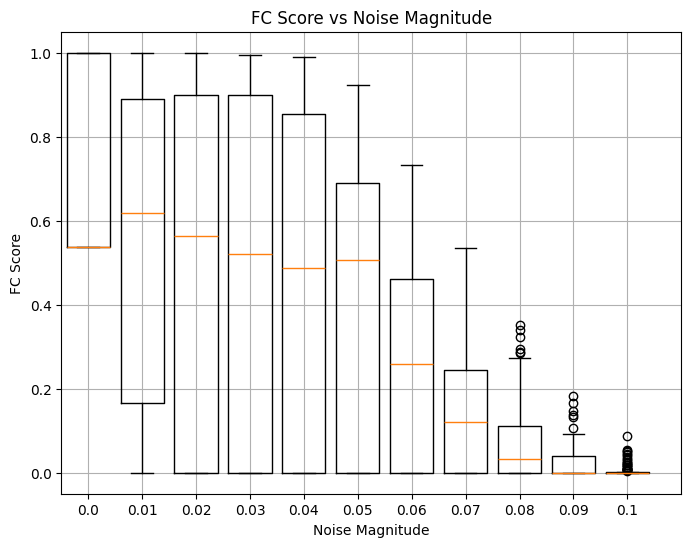

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.boxplot(FC_results.T, positions=noise_magnitudes, widths=0.008)
plt.xlim(-0.005, 0.11)
plt.xlabel("Noise Magnitude")
plt.ylabel("FC Score")
plt.title("FC Score vs Noise Magnitude")
plt.grid()
plt.show()


In [80]:
print(np.mean(FC_results, axis=1))

[0.70340815 0.56560715 0.48882323 0.46342496 0.43991027 0.39429929
 0.25635669 0.13942248 0.07205839 0.02524745 0.00642497]


In [28]:
# save results
import pandas as pd
import xarray as xr

doc_name = "res_temp.nc"

# make numpy arrays into xr.DataArrays
da_FC = xr.DataArray(
    FC_results,
    dims=("red_noise_magnitude", "rep"),
    coords={"red_noise_magnitude": noise_magnitudes, "rep": np.arange(R)},
    name="FC",
)
da_FB = xr.DataArray(
    FB_results,
    dims=("red_noise_magnitude", "rep"),
    coords={"red_noise_magnitude": noise_magnitudes, "rep": np.arange(R)},
    name="FB",
)
da_RC = xr.DataArray(
    RC_results,
    dims=("red_noise_magnitude", "rep"),
    coords={"red_noise_magnitude": noise_magnitudes, "rep": np.arange(R)},
    name="RC",
)
da_Frag = xr.DataArray(
    Frag_results.transpose((1,0,2)),
    dims=("rep", "red_noise_magnitude", "GT_cluster"),
    coords={"red_noise_magnitude": noise_magnitudes, "rep": np.arange(R), "GT_cluster": [1,2]},
    name="Frag",
)
da_Uni = xr.DataArray(
    Uni_results.transpose((1,0,2)),
    dims=("rep", "red_noise_magnitude", "GT_cluster"),
    coords={"red_noise_magnitude": noise_magnitudes, "rep": np.arange(R), "GT_cluster": [1,2]},
    name="Uni",
)

# store dataarray as dataset
ds = xr.Dataset(
    {
        "FC": da_FC,
        "FB": da_FB,
        "RC": da_RC,
        "Frag": da_Frag,
        "Uni": da_Uni,
    }
)

# store parameters as xarray attributes
ds.attrs['index_var'] = "red_noise_magnitude"
ds.attrs['lat_size'] = lat_size
ds.attrs['lon_size'] = lon_size
ds.attrs['time_size'] = time_size
ds.attrs['ac_time'] = ac_time
ds.attrs['shift_magnitude'] = shift_magnitude
ds.attrs['shift_seed1'] = shift_seed1
ds.attrs['shift_seed2'] = shift_seed2
ds.attrs['shape_seed1'] = shape_seed1
ds.attrs['shape_seed2'] = shape_seed2
ds.attrs['det_threshold'] = det_threshold
ds.attrs['min_cluster_size'] = min_cluster_size
ds.attrs['t_unc'] = t_unc

display(ds)

# save to netcdf
#ds.to_netcdf(doc_name)
#print(f"Saved results to {doc_name}")



<xarray.Dataset> Size: 392B
Dimensions:              (red_noise_magnitude: 2, rep: 3, GT_cluster: 2)
Coordinates:
  * red_noise_magnitude  (red_noise_magnitude) float64 16B 0.0 0.01
  * rep                  (rep) int64 24B 0 1 2
  * GT_cluster           (GT_cluster) int64 16B 1 2
Data variables:
    FC                   (red_noise_magnitude, rep) float64 48B 1.0 ... 0.9967
    FB                   (red_noise_magnitude, rep) float64 48B 1.0 ... 0.9984
    RC                   (red_noise_magnitude, rep) float64 48B 1.0 1.0 ... 1.0
    Frag                 (rep, red_noise_magnitude, GT_cluster) float64 96B 1...
    Uni                  (rep, red_noise_magnitude, GT_cluster) float64 96B 1...
Attributes: (12/13)
    index_var:         red_noise_magnitude
    lat_size:          101
    lon_size:          201
    time_size:         100
    ac_time:           1.0
    shift_magnitude:   1.0
    ...                ...
    shift_seed2:       6
    shape_seed1:       2
    shape_seed2:       5
    det_threshold:     0.9
    min_cluster_size:  20
    t_unc:             100

In [14]:
import numpy as np
import xarray as xr

Na = 50
R = 20

a_values = np.linspace(0.0, 1.0, Na)
rep_values = np.arange(R)

result1 = np.random.randn(Na, R)
result2 = np.random.randn(Na, R)
result3 = np.random.randn(Na, R)

da1 = xr.DataArray(
    result1,
    dims=("a", "rep"),
    coords={"a": a_values, "rep": rep_values},
    name="result1",
)

da2 = xr.DataArray(
    result2,
    dims=("a", "rep"),
    coords={"a": a_values, "rep": rep_values},
    name="result2",
)

da3 = xr.DataArray(
    result3,
    dims=("a", "rep"),
    coords={"a": a_values, "rep": rep_values},
    name="result3",
)

ds = xr.Dataset(
    {
        "result1": da1,
        "result2": da2,
        "result3": da3,
    }
)

display(ds)

<xarray.Dataset> Size: 25kB
Dimensions:  (a: 50, rep: 20)
Coordinates:
  * a        (a) float64 400B 0.0 0.02041 0.04082 0.06122 ... 0.9592 0.9796 1.0
  * rep      (rep) int64 160B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
Data variables:
    result1  (a, rep) float64 8kB 0.09689 0.6701 -1.075 ... 0.2282 -1.05 0.1622
    result2  (a, rep) float64 8kB -0.3659 -0.2112 -0.4438 ... 0.2345 1.002
    result3  (a, rep) float64 8kB -0.9301 -0.06579 -0.4408 ... 0.4654 -1.202

## Load Existing Files

In [44]:
# load file
import xarray as xr

doc_name = "data/exp2.nc"

ds_loaded = xr.load_dataset(doc_name)
display(ds_loaded)

<xarray.Dataset> Size: 63kB
Dimensions:              (red_noise_magnitude: 11, rep: 100, GT_cluster: 2)
Coordinates:
  * red_noise_magnitude  (red_noise_magnitude) float64 88B 0.0 0.01 ... 0.09 0.1
  * rep                  (rep) int64 800B 0 1 2 3 4 5 6 ... 93 94 95 96 97 98 99
  * GT_cluster           (GT_cluster) int64 16B 1 2
Data variables:
    FC                   (red_noise_magnitude, rep) float64 9kB 1.0 ... 0.000...
    FB                   (red_noise_magnitude, rep) float64 9kB 1.0 ... 0.09567
    RC                   (red_noise_magnitude, rep) float64 9kB 1.0 ... 0.1429
    Frag                 (rep, red_noise_magnitude, GT_cluster) float64 18kB ...
    Uni                  (rep, red_noise_magnitude, GT_cluster) float64 18kB ...
Attributes: (12/13)
    index_var:         red_noise_magnitude
    lat_size:          101
    lon_size:          201
    time_size:         100
    ac_time:           1.0
    shift_magnitude:   1.0
    ...                ...
    shift_seed2:       6
    shape_seed1:       2
    shape_seed2:       5
    det_threshold:     0.9
    min_cluster_size:  2
    t_unc:             100

(<Figure size 1600x800 with 1 Axes>,
 <GeoAxes: title={'center': 'Cluster Masks'}>)

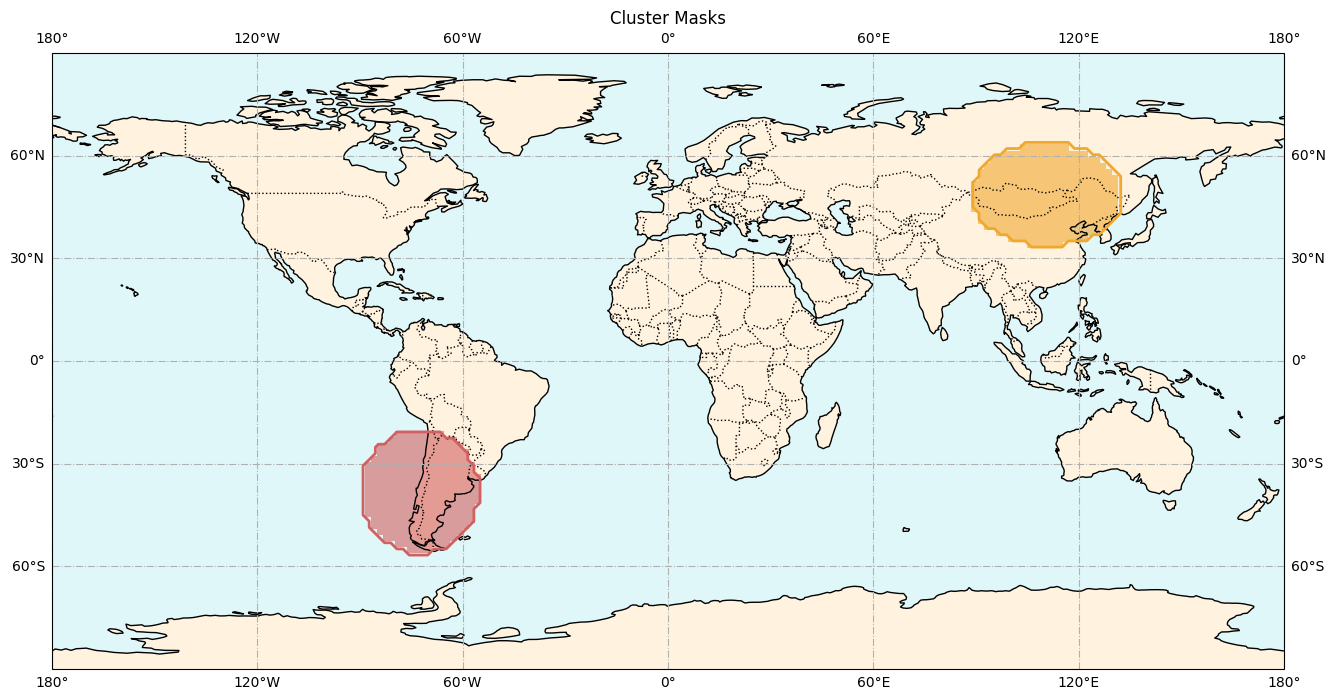

In [45]:
# recreate PONDS object
from ponds import PONDS, SIGMOID, ELLIPSIS ,RedNoise
import matplotlib.pyplot as plt

lat_size = ds_loaded.attrs['lat_size']
lon_size = ds_loaded.attrs['lon_size']
time_size = ds_loaded.attrs['time_size']
pd = PONDS(
    lat_size=lat_size,
    lon_size=lon_size,
    time_size=time_size,
)
ac_time = ds_loaded.attrs['ac_time']
magnitude = 0.01
pd.add_background(
    background_method=RedNoise(
        ac_time=ac_time,
        magnitude=magnitude),
)
pd.add_shift(
    shift_method=SIGMOID(
        shift_magnitude=ds_loaded.attrs['shift_magnitude'],
        shift_seed = ds_loaded.attrs['shift_seed1'],
    ),
    shape_method=ELLIPSIS(
        shape_seed = ds_loaded.attrs['shape_seed1'],
    ),
)
pd.add_shift(
    shift_method=SIGMOID(
        shift_magnitude=ds_loaded.attrs['shift_magnitude'],
        shift_seed = ds_loaded.attrs['shift_seed2'],
    ),
    shape_method=ELLIPSIS(
        shape_seed = ds_loaded.attrs['shape_seed2'],
    ),
)
pd.worldmap()

/tmp/ipykernel_9749/523482232.py:104: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  f"lat_size: {ds_loaded.attrs.get('lat_size')}, lon_size: {ds_loaded.attrs.get('lon_size')}, time_size: {ds_loaded.attrs.get('time_size')}, Repetitions: {ds_loaded.dims.get('rep')}\n"
<frozen _collections_abc>:807: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


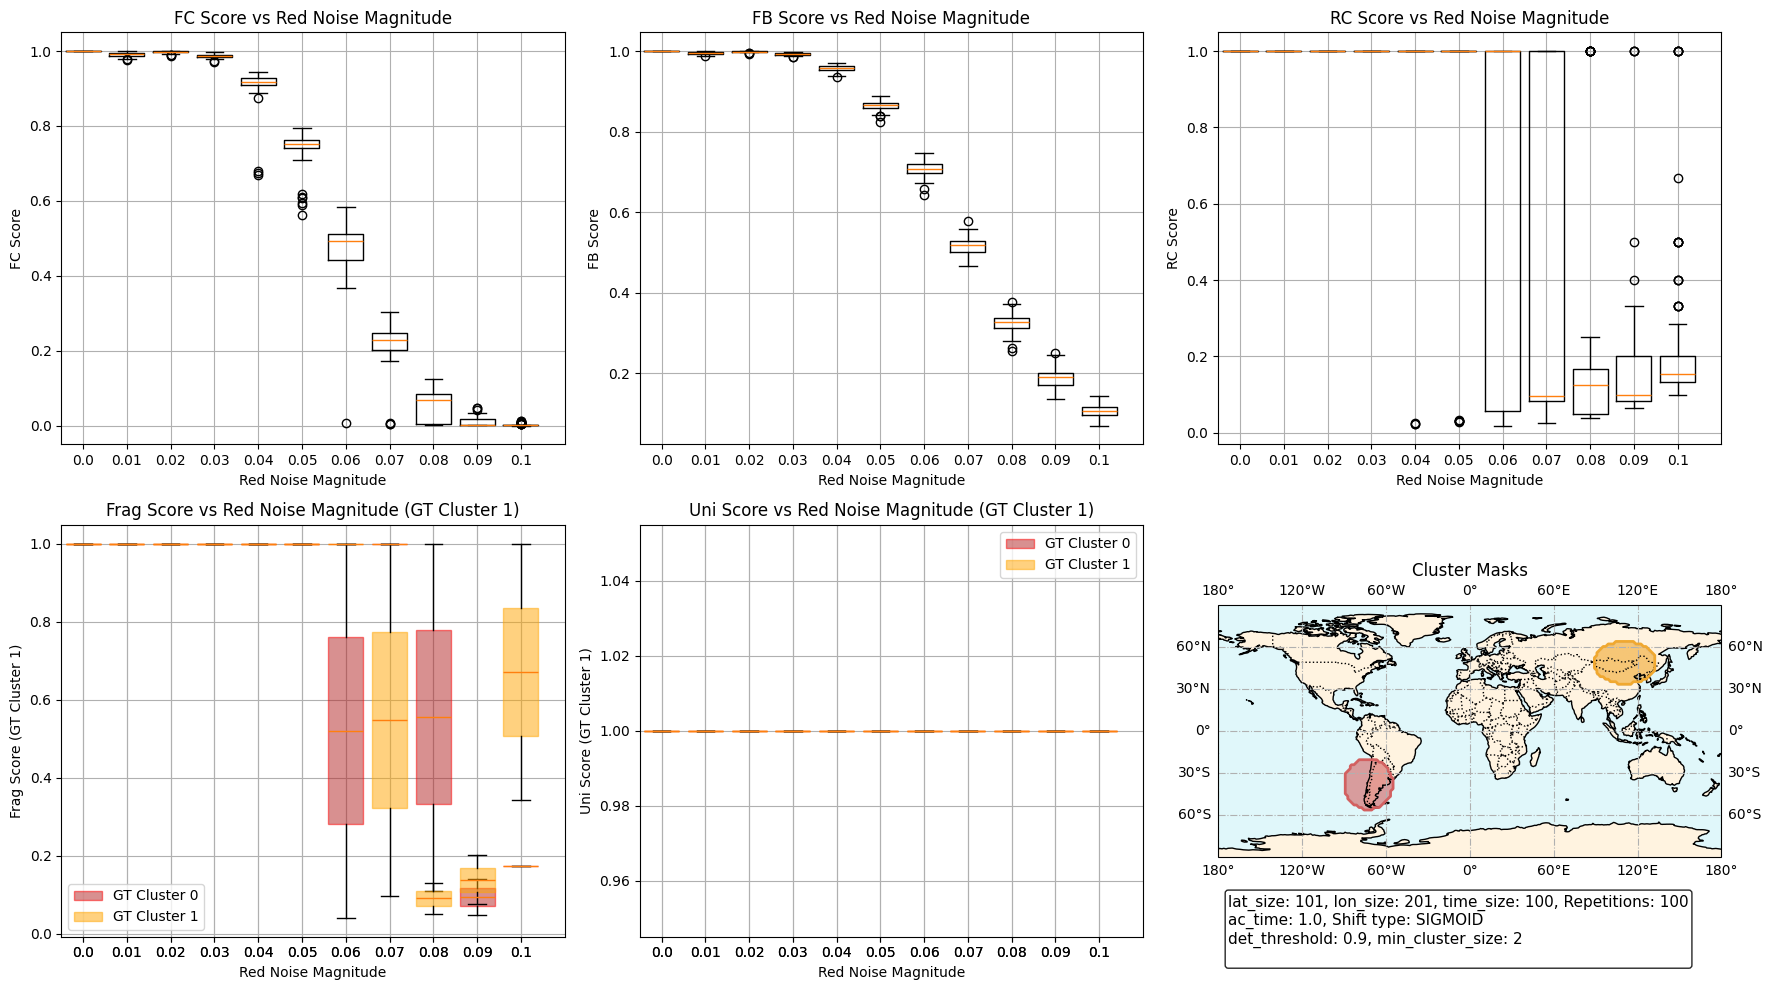

In [46]:
import cartopy.crs as ccrs
import numpy as np
import matplotlib.pyplot as plt

da_FC = ds_loaded["FC"]
da_FB = ds_loaded["FB"]
da_RC = ds_loaded["RC"]
da_Frag = ds_loaded["Frag"]
da_Uni = ds_loaded["Uni"]

# extracts variable values
noise_magnitudes = da_FC["red_noise_magnitude"].to_numpy()
# extract values as numpy array 
vals_FC = da_FC.to_numpy().T
vals_FB = da_FB.to_numpy().T
vals_RC = da_RC.to_numpy().T
vals_Frag = da_Frag.to_numpy().T
vals_Uni = da_Uni.to_numpy().T

# plot
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3)

ax = np.empty((2, 3), dtype=object)

ax[0, 0] = fig.add_subplot(gs[0, 0])
ax[0, 1] = fig.add_subplot(gs[0, 1])
ax[0, 2] = fig.add_subplot(gs[0, 2])

ax[1, 0] = fig.add_subplot(gs[1, 0])
ax[1, 1] = fig.add_subplot(gs[1, 1])

# Cartopy axis
ax[1, 2] = fig.add_subplot(
    gs[1, 2],
    projection=ccrs.PlateCarree()
)


# FC scoring boxplot
ax[0, 0].boxplot(vals_FC, positions=noise_magnitudes, widths=0.008)
ax[0, 0].set_xlim(-0.005, 0.11)
ax[0, 0].set_xlabel("Red Noise Magnitude")
ax[0, 0].set_ylabel("FC Score")
ax[0, 0].set_title("FC Score vs Red Noise Magnitude")
ax[0, 0].grid()

# FB scoring boxplot
ax[0, 1].boxplot(vals_FB, positions=noise_magnitudes, widths=0.008)
ax[0, 1].set_xlim(-0.005, 0.11)
ax[0, 1].set_xlabel("Red Noise Magnitude")
ax[0, 1].set_ylabel("FB Score")
ax[0, 1].set_title("FB Score vs Red Noise Magnitude")
ax[0, 1].grid()

# RC scoring boxplot
ax[0, 2].boxplot(vals_RC, positions=noise_magnitudes, widths=0.008)
ax[0, 2].set_xlim(-0.005, 0.11)
ax[0, 2].set_xlabel("Red Noise Magnitude")
ax[0, 2].set_ylabel("RC Score")
ax[0, 2].set_title("RC Score vs Red Noise Magnitude")
ax[0, 2].grid()

# Frag scoring boxplot
bp1 = ax[1, 0].boxplot(vals_Frag[:, :, 0], patch_artist=True, positions=noise_magnitudes, widths=0.008)
bp2 = ax[1, 0].boxplot(vals_Frag[:, :, 1], patch_artist=True, positions=noise_magnitudes, widths=0.008)
ax[1, 0].set_xlim(-0.005, 0.11)
ax[1, 0].set_xlabel("Red Noise Magnitude")
ax[1, 0].set_ylabel("Frag Score (GT Cluster 1)")
ax[1, 0].set_title("Frag Score vs Red Noise Magnitude (GT Cluster 1)")
ax[1, 0].grid()

for box in bp1['boxes']:
    box.set(color='red')
    box.set(facecolor = 'firebrick', alpha=0.5 )
for box in bp2['boxes']:
    box.set(color='orange')
    box.set(facecolor = 'orange', alpha=0.5 )

ax[1, 0].legend([bp1["boxes"][0], bp2["boxes"][0]], ['GT Cluster 0', 'GT Cluster 1'])


# Uni scoring boxplot
bp1 = ax[1, 1].boxplot(vals_Uni[:, :, 0], patch_artist=True, positions=noise_magnitudes, widths=0.008)
bp2 = ax[1, 1].boxplot(vals_Uni[:, :, 1], patch_artist=True, positions=noise_magnitudes, widths=0.008)
ax[1, 1].set_xlim(-0.005, 0.11)
ax[1, 1].set_xlabel("Red Noise Magnitude")
ax[1, 1].set_ylabel("Uni Score (GT Cluster 1)")
ax[1, 1].set_title("Uni Score vs Red Noise Magnitude (GT Cluster 1)")
ax[1, 1].grid()

for box in bp1['boxes']:
    box.set(color='red')
    box.set(facecolor = 'firebrick', alpha=0.5 )
for box in bp2['boxes']:
    box.set(color='orange')
    box.set(facecolor = 'orange', alpha=0.5 )

ax[1, 1].legend([bp1["boxes"][0], bp2["boxes"][0]], ['GT Cluster 0', 'GT Cluster 1'])

# Worldmap + metadata box
pd.worldmap(ax=ax[1, 2])
txt = (
    f"lat_size: {ds_loaded.attrs.get('lat_size')}, lon_size: {ds_loaded.attrs.get('lon_size')}, time_size: {ds_loaded.attrs.get('time_size')}, Repetitions: {ds_loaded.dims.get('rep')}\n"
    f"ac_time: {ds_loaded.attrs.get('ac_time')}, Shift type: SIGMOID\n"
    f"det_threshold: {ds_loaded.attrs.get('det_threshold')}, min_cluster_size: {ds_loaded.attrs.get('min_cluster_size')}\n"
)
ax_box = ax[1, 2]
ax_box.text(
    0.02,
    -0.15,
    txt,
    transform=ax_box.transAxes,
    fontsize=11,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="k"),
)

plt.tight_layout()
plt.show()

## Scan Autocorrelation Time

(<Figure size 1600x400 with 1 Axes>,
 <Axes: title={'center': 'Time Series for Some Example Cells'}, xlabel='Time', ylabel='Value'>)

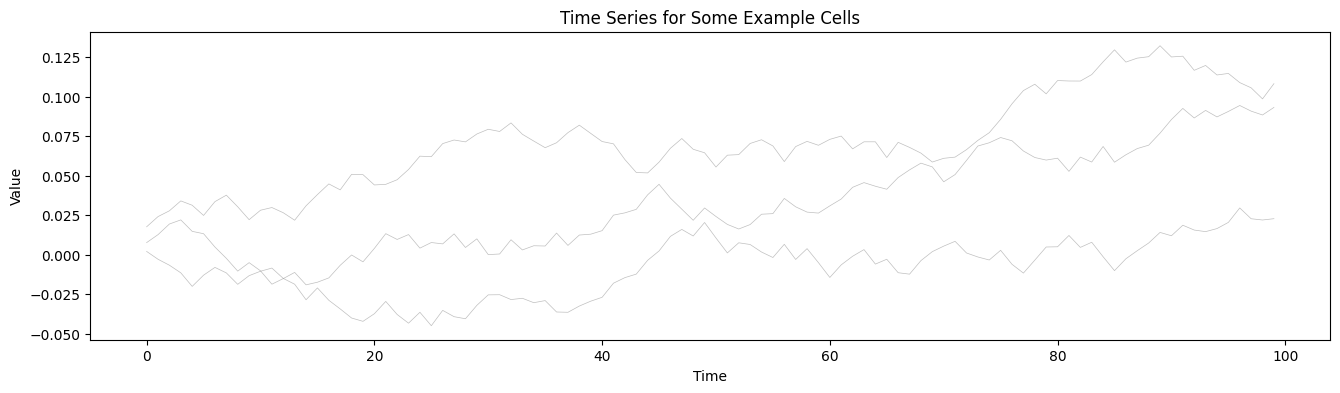

In [57]:
from ponds import PONDS, SIGMOID, ELLIPSIS ,RedNoise
import matplotlib.pyplot as plt
import numpy as np

# ponds parameters
lat_size = 101
lon_size = 201
time_size = 100
noise_magnitude = 0.01
shift_seed = 5
shape_seed = 2

# scan parameters
ac_time = np.inf

pd = PONDS(
    lat_size=lat_size,
    lon_size=lon_size,
    time_size=time_size,
)

pd.add_background(
    background_method=RedNoise(
        ac_time=ac_time,
        magnitude=noise_magnitude),
)

pd.plot_some_ts(
    ratio=0.0001
)